# Onde o peixe-leão vai chegar a seguir, e quando?

O peixe-leão (*Pterois volitans* e *P. miles*), nativo do Indo-Pacífico, invadiu o Atlântico oeste a partir da
Flórida e, pelo Canal de Suez, o Mediterrâneo. A decisão que este estudo informa é onde concentrar vigilância e
detecção precoce nos próximos anos.

O caminho: (1) reconstruir a frente de invasão com registros públicos; (2) medir a velocidade da frente sem se
enganar com a detecção imperfeita; (3) ajustar um modelo de espalhamento e conferi-lo no tempo, contra duas regras
simples; (4) prever, com faixa de incerteza.

É análise de dado público agregado, feita por um profissional de dados, não por um biólogo. Os números vêm de
`reports/resultados.json`; o método está em `src/peixe_leao/` e é conferido em `tests/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from peixe_leao import analise, dados, frente, graficos

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
r = json.loads(Path("reports/resultados.json").read_text(encoding="utf-8"))
base = dados.carregar()
teatros = {chave: analise.montar_teatro(base, chave) for chave in ("atlantico", "mediterraneo")}


def mostrar(figura):
    display(figura)
    plt.close(figura)


print("Coleta:", r["coleta"]["data"])

Coleta: 2026-11-12


## 1. Do registro bruto ao dado central

Três fontes públicas, sem chave: o banco de espécies aquáticas não nativas do USGS (NAS), o GBIF e o OBIS. O funil
abaixo mostra o que cada filtro tira. Dois pontos pedem atenção:

- **o GBIF devolve registros de ausência** (censos que procuraram o peixe e não acharam) na mesma busca. Eles não
  são baixados; a contagem está na segunda tabela;
- **as três fontes se repetem**: o NAS é republicado dentro do GBIF e do OBIS, e a mesma observação de ciência
  cidadã aparece nas duas redes.

In [2]:
funil = pd.DataFrame(r["coleta"]["funil"]).set_index("passo")
display(funil)
display(pd.Series(r["coleta"]["ausencias_no_gbif"], name="registros de ausência no GBIF (não baixados)").to_frame())

,total,NAS,GBIF,OBIS
passo,,,,
Registros baixados (gênero Pterois nas caixas dos dois teatros; NAS inteiro),40376,12419,15208,12749
Com coordenada e ano,39558,12419,15208,11931
"Dentro da área invadida (fora do Pacífico, do Mar Vermelho e do Mar Negro)",39553,12419,15205,11929
Sem espécime vivo de coleção ou aquário,39541,12418,15194,11929
Com ano entre a introdução e o último ano completo,38468,12379,14518,11571
Sem duplicata entre fontes,13603,7127,5046,1430
"Sem coordenada em terra (ponto e vizinhos de 0,1 grau acima do nível do mar)",13544,7117,4998,1429
"Em célula de plataforma, ou a até uma célula de distância (fica na mais próxima)",13349,7070,4850,1429
Servem para datar a chegada (têm outro registro por perto em até 3 anos),13284,7053,4823,1408


,registros de ausência no GBIF (não baixados)
atlantico,26861
mediterraneo,3131


O dado central é o **ano do primeiro registro corroborado** em cada célula de 1° da plataforma continental (0 a
300 m de profundidade). "Corroborado" quer dizer que há outro registro na mesma célula ou numa vizinha, no mesmo ano
ou nos três seguintes. Um registro sozinho pode ser erro de data, de identificação ou um animal solto que não deixou
população.

A tabela compara os dados com a cronologia publicada. A coluna do registro bruto mostra onde os dados públicos
discordam da literatura; a do registro corroborado, o que a regra faz com isso.

In [3]:
display(pd.DataFrame(r["cronologia"]))
display(pd.DataFrame({chave: {k: v for k, v in valor.items() if k != "mais_antigos"} for chave, valor in r["registros_que_contradizem"].items()}))

,marco,ano_na_literatura,fonte,ano_bruto_nos_dados,ano_corroborado_nos_dados
0,"Flórida, costa atlântica (Dania)",1985,Schofield 2009,1985,1990
1,Bermudas,2000,Schofield 2009,2000,2000
2,Bahamas,2004,Schofield 2009,2004,2004
3,"Mar do Caribe (Turks e Caicos, Cuba)",2007,Schofield 2009,1996,2007
4,Golfo do México,2009,Schofield 2010,2009,2009
5,Venezuela,2009,Schofield 2010,2009,2009
6,"Brasil, registro isolado (Arraial do Cabo)",2014,Ferreira et al. 2015,2014,2014
7,"Brasil, costa norte e Fernando de Noronha",2020,Luiz et al. 2021,2020,2020
8,"Brasil, Ceará e Piauí",2022,Soares et al. 2022,2022,2022
9,Israel (primeiro do Mediterrâneo),1991,Golani e Sonin 1992,1991,2014


,atlantico,mediterraneo
celulas_com_registro_bruto,254,92
celulas_com_registro_corroborado,248,86
celulas_em_que_o_bruto_e_mais_antigo,5,11
celulas_so_com_registro_isolado,6,6
ano_minimo_para_datar,1985,2012
celulas_com_registro_bruto_antes_do_ano_minimo,0,14


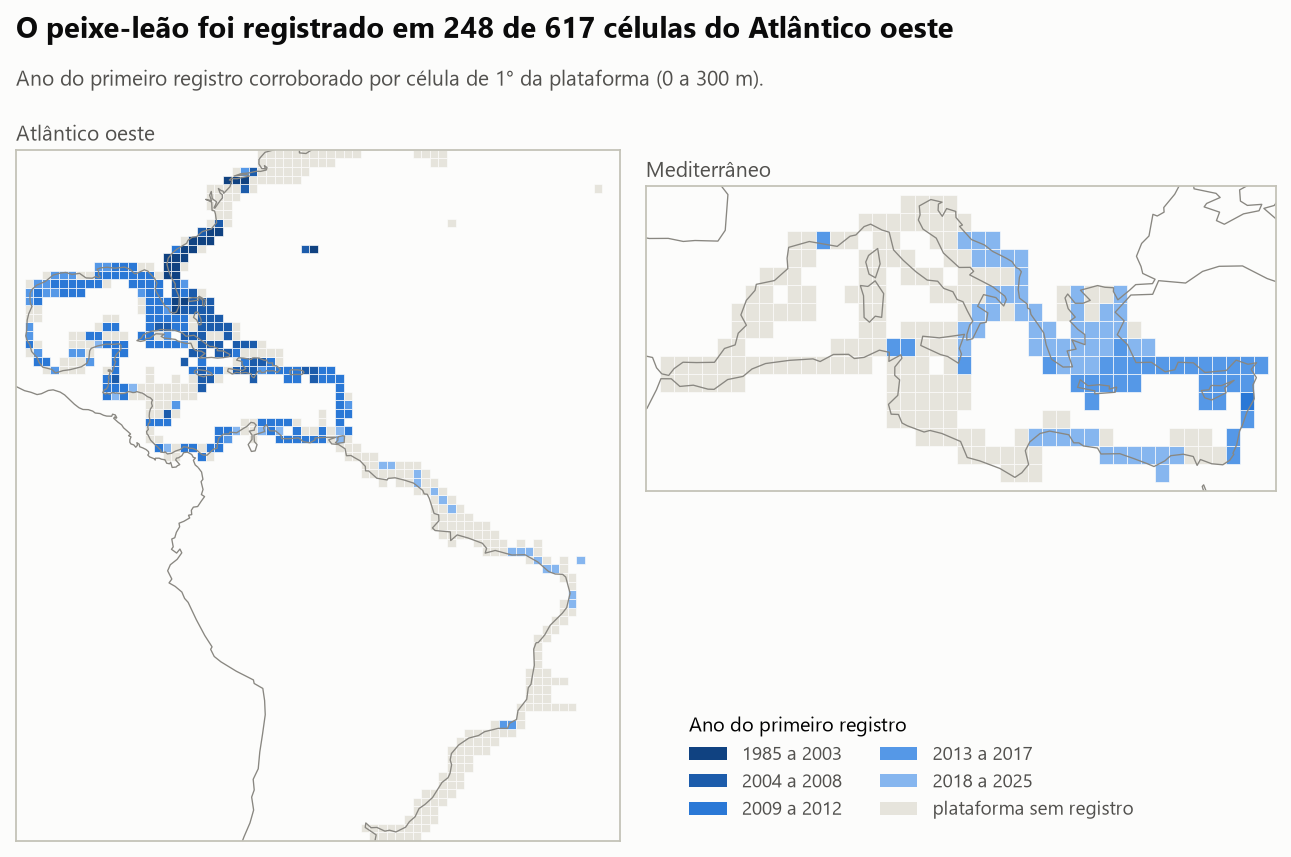

,atlantico,mediterraneo
celulas_de_plataforma,617,237
celulas_com_registro,248,86
fracao_com_registro,0.40,0.36
celulas_so_com_registro_nao_corroborado,6,6
celulas_com_ano_alterado_pela_corroboracao,5,11
primeiro_ano,1990,2012
ano_de_inicio_da_expansao,2000,2012
celulas_semente,6,1
ano_de_pico,2009,2019
novas_celulas_no_pico,48,18


In [4]:
atl, med = r["teatros"]["atlantico"], r["teatros"]["mediterraneo"]
mostrar(graficos.mapa_do_primeiro_registro(
    base["celulas"], base["costa"],
    f"O peixe-leão foi registrado em {atl['celulas_com_registro']} de {atl['celulas_de_plataforma']} células do Atlântico oeste",
    "Ano do primeiro registro corroborado por célula de 1° da plataforma (0 a 300 m).",
))
display(pd.DataFrame({chave: {k: v for k, v in valor.items() if k not in ("area_e_frente", "fontes_do_primeiro_registro")} for chave, valor in r["teatros"].items()}))

## 2. A velocidade da frente

"Avança X km por ano" é a conta que todo mundo faz: a distância ao ponto de introdução contra o ano do primeiro
registro, por mínimos quadrados. Ela tem dois problemas. A frente é quem foi mais longe em cada época, não a média,
porque as células atrás da frente continuam sendo ocupadas por anos. E o primeiro registro vem depois da chegada, com
atraso maior onde há menos gente olhando.

Antes de aplicar qualquer estimador aos dados, ele é testado numa **invasão simulada com velocidade conhecida** (250
km por ano), em quatro cenários de dificuldade crescente.

cenario,"Detecção perfeita, sem preenchimento",Preenchimento atrás da frente,Preenchimento e detecção imperfeita,"Idem, com menos esforço longe da origem"
estimador,,,,
Frente: envelope dos recordes,0.00,-0.50,-0.40,-4.70
"Frente: quantil 0,10 do ano",0.10,0.80,2.50,-0.20
"Frente: quantil 0,90 da distância",0.00,-1.40,-2.70,-9.70
Média: ano contra distância,0.20,7.70,17.80,11.50
"Média: ano contra distância, com esforço",0.20,7.70,15.60,27.70
Média: distância contra ano (linha de base),0.00,-7.70,-15.40,-31.20


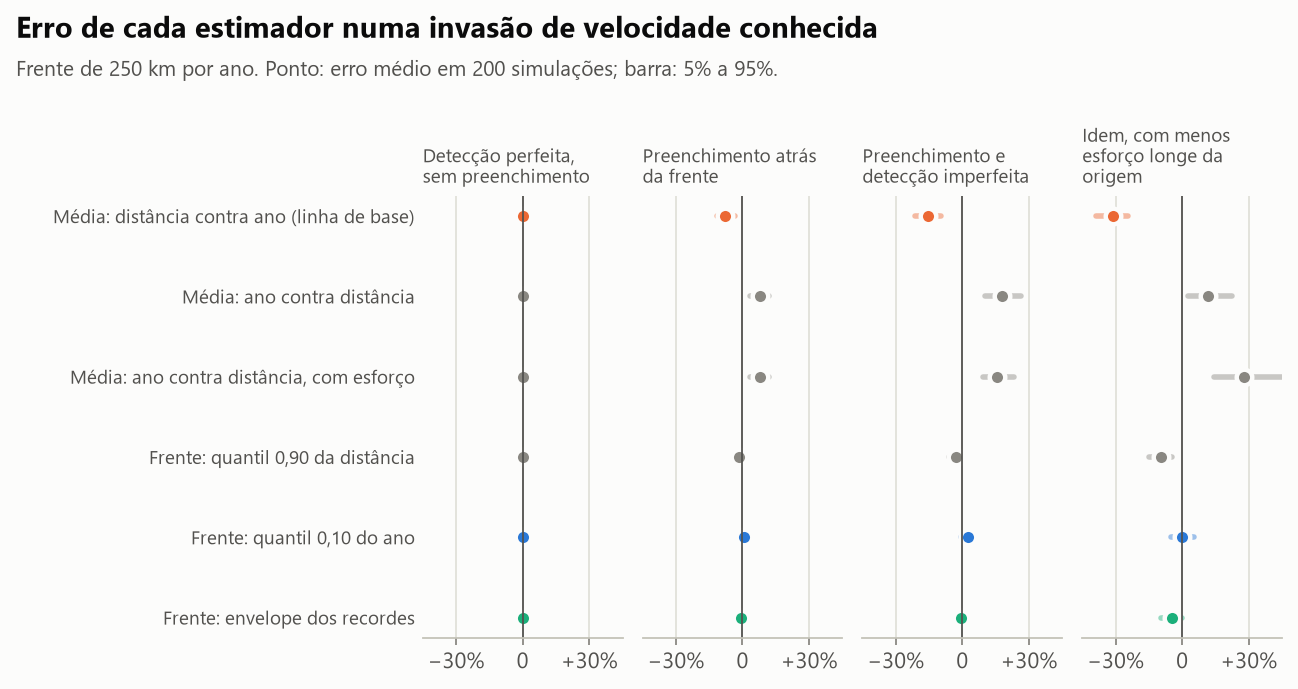

In [5]:
sim = pd.DataFrame(r["velocidade"]["simulacao"])
display((sim.pivot(index="estimador", columns="cenario", values="erro_relativo") * 100).round(1)[list(dict.fromkeys(sim["cenario"]))])
mostrar(graficos.erro_dos_estimadores(sim, "Erro de cada estimador numa invasão de velocidade conhecida", "Frente de 250 km por ano. Ponto: erro médio em 200 simulações; barra: 5% a 95%."))

Nos dados reais, a velocidade é medida no ramo que avança (no Atlântico, o do sul e do oeste; o ramo norte, pela
costa leste dos EUA, é levado pela Corrente do Golfo e não passa o inverno). O intervalo é de 95%, por bootstrap de
células.

In [6]:
for chave in teatros:
    print(chave)
    display(pd.DataFrame(r["velocidade"]["dados_reais"][chave]).T.round(0))
display(pd.DataFrame(r["velocidade"]["esforco_e_atraso"]))

atlantico


,km_por_ano,inferior,superior,celulas
Média: distância contra ano (linha de base),186.00,143.00,230.00,214.00
Média: ano contra distância,393.00,353.00,446.00,214.00
"Média: ano contra distância, com esforço",392.00,352.00,442.00,214.00
"Frente: quantil 0,90 da distância",309.00,267.00,325.00,214.00
"Frente: quantil 0,10 do ano",406.00,373.00,594.00,214.00
Frente: envelope dos recordes,323.00,284.00,376.00,214.00


mediterraneo


,km_por_ano,inferior,superior,celulas
Média: distância contra ano (linha de base),124.00,87.00,155.00,85.00
Média: ano contra distância,353.00,245.00,569.00,85.00
"Média: ano contra distância, com esforço",309.00,223.00,498.00,85.00
"Frente: quantil 0,90 da distância",83.00,-26.00,184.00,85.00
"Frente: quantil 0,10 do ano",886.00,252.00,"1,983.00",85.00
Frente: envelope dos recordes,653.00,139.00,"1,054.00",85.00


,atlantico,mediterraneo
celulas,214.00,85.00
correlacao_esforco_distancia,0.20,0.49
p_esforco_distancia,0.00,0.00
correlacao_esforco_atraso,0.05,0.08
p_esforco_atraso,0.51,0.45
atraso_mediano_pouco_esforco_anos,1.99,3.18
atraso_mediano_muito_esforco_anos,3.04,3.93
esforco_mediano,2.67,2.67


## 3. O modelo de espalhamento e a validação no tempo

O modelo descreve o primeiro registro de cada célula, ano a ano: o risco cresce com a proximidade (pelo mar) de
células já ocupadas e com o esforço de observação; uma fração das células não é suscetível (sem recife, fria demais
ou sem observador), e essa fração depende do habitat e da temperatura do mês mais frio.

A validação é a de quem não conhece o futuro: o modelo é ajustado com o que se sabia até um ano de corte e prevê os
anos seguintes. Ao lado dele, as duas regras simples (velocidade constante e célula vizinha) e duas versões
reduzidas do próprio modelo.

In [7]:
linhas = []
for nome, v in r["validacao"].items():
    for horizonte, h in v["horizontes"].items():
        for metodo, rotulo in r["rotulos_dos_metodos"].items():
            m = h[metodo]
            linhas.append({
                "teatro e corte": nome.replace("_", ", até "), "horizonte (anos)": int(horizonte), "método": rotulo,
                "AUC": m["auc"], "AUC inf.": m["auc_ic"][0], "AUC sup.": m["auc_ic"][1], "Brier": m["brier"],
                "células previstas": m["previstas"], "células colonizadas": h["colonizadas"],
            })
display(pd.DataFrame(linhas).set_index(["teatro e corte", "horizonte (anos)", "método"]).round(3))

AUC  \
teatro e corte         horizonte (anos) método                                          
atlantico, até 2010    5                Modelo de espalhamento (completo)        0.84   
                                        Modelo sem temperatura                   0.81   
                                        Modelo sem fração suscetível (1ª versão) 0.83   
                                        Velocidade constante                     0.76   
                                        Célula vizinha                           0.84   
                       10               Modelo de espalhamento (completo)        0.81   
                                        Modelo sem temperatura                   0.77   
                                        Modelo sem fração suscetível (1ª versão) 0.82   
                                        Velocidade constante                     0.75   
                                        Célula vizinha                           0.82   
atlantico, até 2018    5                Modelo de espalhamento (completo)        0.77   
                                        Modelo sem temperatura                   0.63   
                                        Modelo sem fração suscetível (1ª versão) 0.52   
                                        Velocidade constante                     0.50   
                                        Célula vizinha                           0.60   
mediterraneo, até 2018 5                Modelo de espalhamento (completo)        0.78   
                                        Modelo sem temperatura                   0.79   
                                        Modelo sem fração suscetível (1ª versão) 0.79   
                                        Velocidade constante                     0.57   
                                        Célula vizinha                           0.74   

                                                                                  AUC inf.  \
teatro e corte         horizonte (anos) método                                               
atlantico, até 2010    5                Modelo de espalhamento (completo)             0.77   
                                        Modelo sem temperatura                        0.74   
                                        Modelo sem fração suscetível (1ª versão)      0.77   
                                        Velocidade constante                          0.72   
                                        Célula vizinha                                0.79   
                       10               Modelo de espalhamento (completo)             0.74   
                                        Modelo sem temperatura                        0.69   
                                        Modelo sem fração suscetível (1ª versão)      0.77   
                                        Velocidade constante                          0.71   
                                        Célula vizinha                                0.77   
atlantico, até 2018    5                Modelo de espalhamento (completo)             0.69   
                                        Modelo sem temperatura                        0.55   
                                        Modelo sem fração suscetível (1ª versão)      0.41   
                                        Velocidade constante                          0.40   
                                        Célula vizinha                                0.48   
mediterraneo, até 2018 5                Modelo de espalhamento (completo)             0.69   
                                        Modelo sem temperatura                        0.71   
                                        Modelo sem fração suscetível (1ª versão)      0.71   
                                        Velocidade constante                          0.55   
                                        Célula vizinha                                0.66   

                                                      

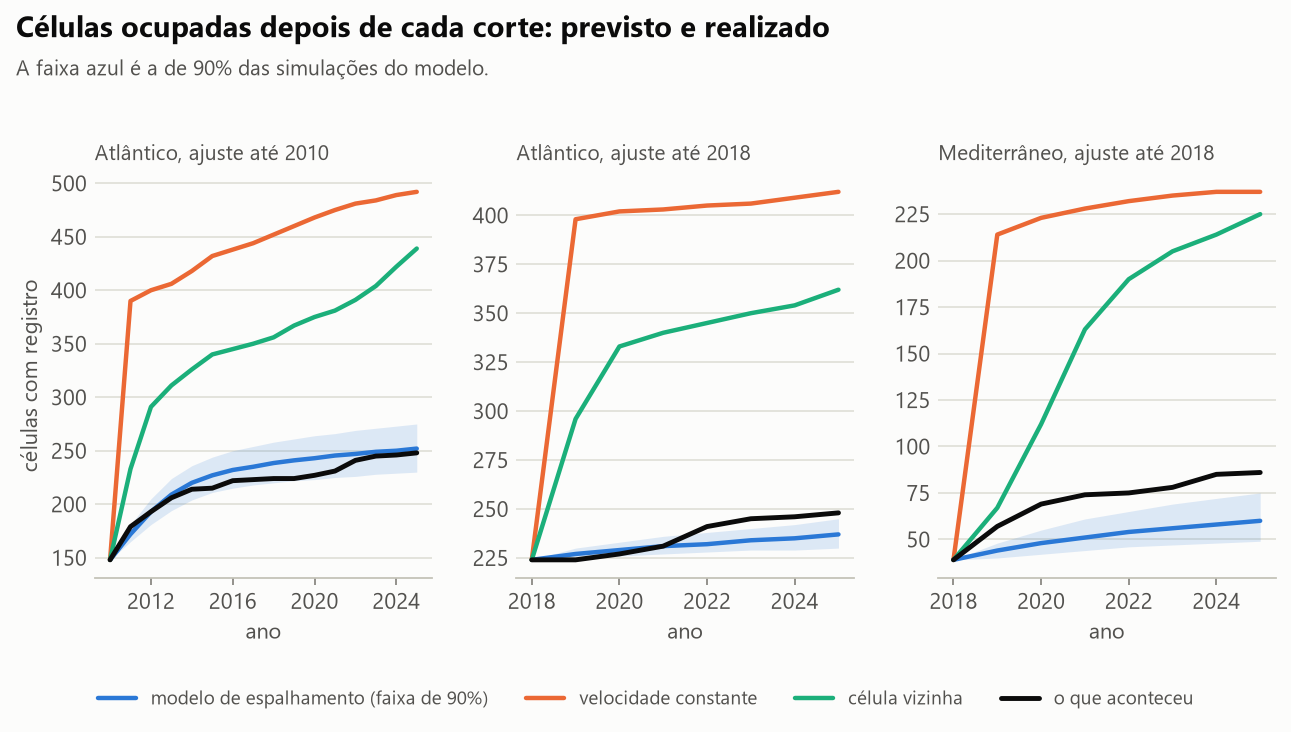

In [8]:
paineis = [
    {"rotulo": "Atlântico, ajuste até 2010", "curvas": r["validacao"]["atlantico_2010"]["curvas"]},
    {"rotulo": "Atlântico, ajuste até 2018", "curvas": r["validacao"]["atlantico_2018"]["curvas"]},
    {"rotulo": "Mediterrâneo, ajuste até 2018", "curvas": r["validacao"]["mediterraneo_2018"]["curvas"]},
]
mostrar(graficos.validacao(paineis, "celulas", "células com registro", "Células ocupadas depois de cada corte: previsto e realizado", "A faixa azul é a de 90% das simulações do modelo."))

### O teste difícil: a foz do Amazonas e a chegada ao Brasil

A tabela mostra, para cada corte, o que o modelo e as regras simples diziam sobre regiões que ainda não tinham
registro. A linha das Guianas é a que mostra o erro de caminho: o modelo esperava a passagem por ali bem antes do
primeiro registro.

In [9]:
linhas = []
for nome, v in r["validacao"].items():
    for regiao, x in v["regioes"].items():
        linhas.append({
            "corte": nome.replace("_", ", até "), "região": regiao, "1º registro observado": x["ano_observado_do_primeiro_registro"],
            "modelo: mediana": x["ano_mediano_previsto"], "modelo: 5%": x["ano_previsto_p05"], "modelo: 95%": x["ano_previsto_p95"],
            "prob. de algum registro até 2025": x["probabilidade_de_algum_registro_ate_o_ano_final"],
            "velocidade constante": x["ano_velocidade_constante"], "célula vizinha": x["ano_vizinha"],
        })
display(pd.DataFrame(linhas).set_index(["corte", "região"]))
display(pd.DataFrame({nome: {metodo: f"{x['erro_absoluto_medio']:.1f} ({x['vies']:+.1f})" for metodo, x in v["erro_no_ano"].items() if metodo != "celulas"} for nome, v in r["validacao"].items()}).rename(index=r["rotulos_dos_metodos"]))

1º registro observado  \
corte                  região                                                               
atlantico, até 2010    Costa brasileira                                          2,020.00   
                       Brasil ao sul de 13°S                                          NaN   
                       Guianas (Guiana, Suriname, Guiana Francesa)               2,021.00   
                       EUA ao norte do Cabo Hatteras                             2,014.00   
atlantico, até 2018    Costa brasileira                                          2,020.00   
                       Brasil ao sul de 13°S                                          NaN   
                       Guianas (Guiana, Suriname, Guiana Francesa)               2,021.00   
                       EUA ao norte do Cabo Hatteras                                  NaN   
mediterraneo, até 2018 Mediterrâneo ocidental (a oeste de 12°L)                       NaN   
                       Adriático                                                 2,019.00   
                       Mediterrâneo oriental (a leste de 22°L)                   2,019.00   

                                                                    modelo: mediana  \
corte                  região                                                         
atlantico, até 2010    Costa brasileira                                    2,017.00   
                       Brasil ao sul de 13°S                                    NaN   
                       Guianas (Guiana, Suriname, Guiana Francesa)         2,012.00   
                       EUA ao norte do Cabo Hatteras                       2,012.00   
atlantico, até 2018    Costa brasileira                                    2,024.00   
                       Brasil ao sul de 13°S                                    NaN   
                       Guianas (Guiana, Suriname, Guiana Francesa)         2,020.00   
                       EUA ao norte do Cabo Hatteras                       2,022.00   
mediterraneo, até 2018 Mediterrâneo ocidental (a oeste de 12°L)            2,019.00   
                       Adriático                                           2,023.00   
                       Mediterrâneo oriental (a leste de 22°L)             2,019.00   

                                                                    modelo: 5%  \
corte                  região                                                    
atlantico, até 2010    Costa brasileira                               2,013.00   
                       Brasil ao sul de 13°S                               NaN   
                       Guianas (Guiana, Suriname, Guiana Francesa)    2,011.00   
                       EUA ao norte do Cabo Hatteras                  2,011.00   
atlantico, até 2018    Costa brasileira                               2,019.00   
                       Brasil ao sul de 13°S                          2,020.00   
                       Guianas (Guiana, Suriname, Guiana Francesa)    2,019.00   
                       EUA ao norte do Cabo Hatteras                  2,019.00   
mediterraneo, até 2018 Mediterrâneo ocidental (a oeste de 12°L)       2,019.00   
                       Adriático                                      2,019.00   
                       Mediterrâneo oriental (a leste de 22°L)        2,019.00   

                                                                    modelo: 95%  \
corte                  região                                                     
atlantico, até 2010    Costa brasileira                                2,024.00   
                       Brasil ao sul de 13°S                                NaN   
                       Guianas (Guiana, Suriname, Guiana Francesa)     2,015.00   
                       EUA ao norte do Cabo Hatteras                        NaN   
atlantico, até 2018    Costa brasileira                                     NaN   
                       Brasil ao sul de 13°S                                Na

,atlantico_2010,atlantico_2018,mediterraneo_2018
Modelo de espalhamento (completo),4.1 (+1.0),3.2 (+2.3),1.6 (+0.5)
Modelo sem temperatura,4.1 (+1.1),3.4 (+2.5),1.3 (+0.7)
Modelo sem fração suscetível (1ª versão),2.6 (+0.6),2.5 (+1.4),1.4 (+1.1)
Velocidade constante,2.8 (-1.9),4.0 (+1.6),1.7 (-1.7)
Célula vizinha,2.8 (-0.7),3.8 (+1.4),1.2 (-0.1)


## 4. A previsão para os próximos dez anos

O modelo é reajustado com todos os dados até 2025 e simulado até 2035. A tabela completa, por célula, está em
`reports/probabilidade_de_chegada.csv`. **É um exercício de modelagem, não uma previsão oficial.**

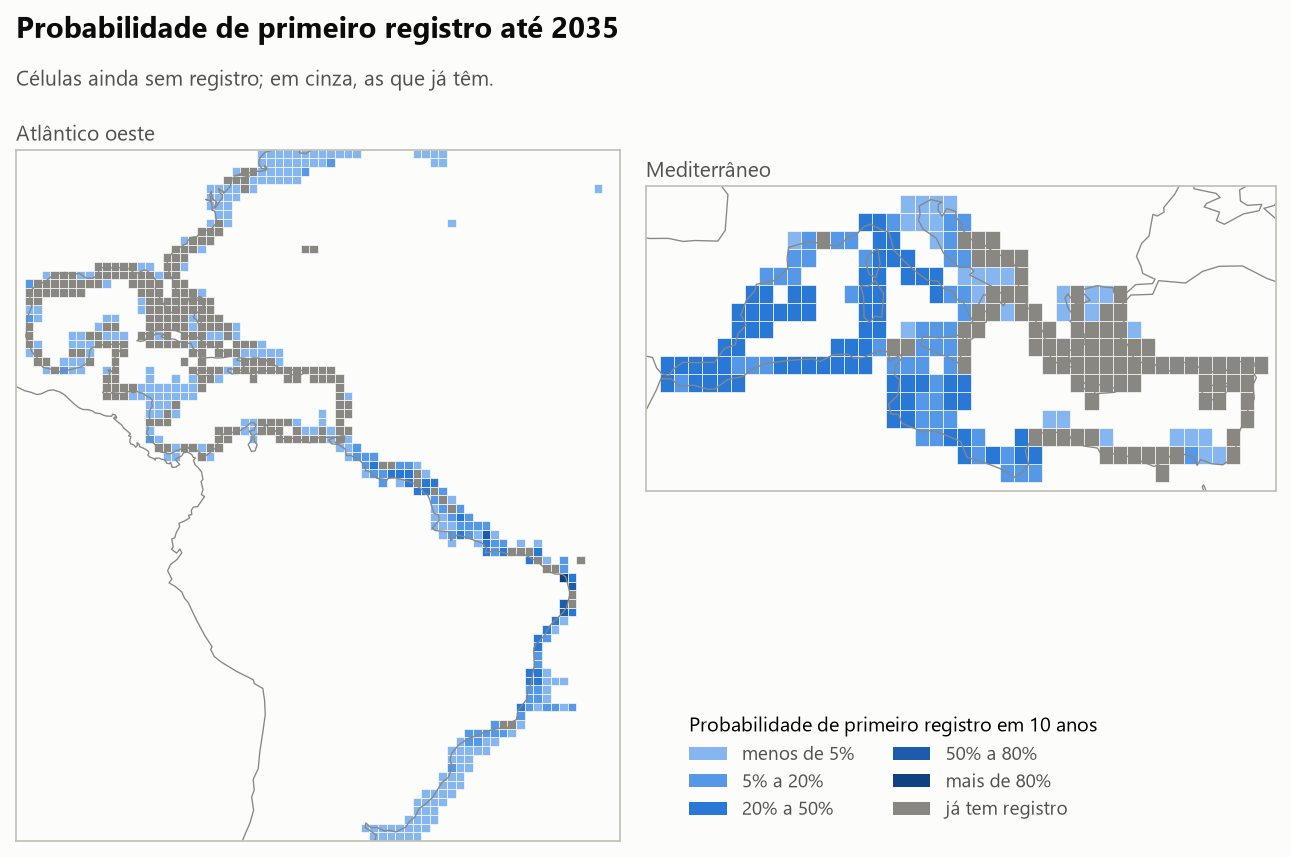

atlantico | parâmetros: {'alcance_km': 477.172, 'elasticidade_esforco': 0.124, 'contagio': 0.025, 'fundo': 0.001, 'log_verossimilhanca': -817.006, 'aic': 1648.012, 'parametros': 7, 'eventos': 242, 'celulas_ano_em_risco': 11783, 'suscetivel_constante': -2.999, 'suscetivel_inclinacao_do_habitat': 0.777, 'limite_termico_c': 7.095, 'celulas_sem_registro': 369, 'suscetiveis_esperadas_entre_as_sem_registro': 57.986}


,celulas,celulas_sem_registro,prob_de_algum_registro_novo_em_5_anos,prob_de_algum_registro_novo_em_10_anos,prob_10_anos_faixa,novas_celulas_esperadas_em_5_anos,novas_celulas_esperadas_em_10_anos,maior_prob_10_anos,celulas_abaixo_de_16_1
Costa brasileira,132,118,1.00,1.00,"[1.0, 1.0]",6.79,13.86,0.88,7
Brasil ao sul de 13°S,68,66,0.61,0.89,"[0.82, 0.96]",1.29,4.25,0.37,7
"Guianas (Guiana, Suriname, Guiana Francesa)",21,17,0.86,0.96,"[0.889, 1.0]",1.93,2.87,0.43,0
EUA ao norte do Cabo Hatteras,83,76,0.29,0.42,"[0.249, 0.591]",0.35,0.57,0.07,75


,celula,regiao,lat_sul,lon_oeste,prob_suscetivel,prob_5_anos,prob_10_anos,prob_10_anos_inf,prob_10_anos_sup,tmin_c
0,A_S06_W036,Costa brasileira,-6,-36,0.98,0.64,0.88,0.78,0.94,26.24
1,A_S09_W036,Costa brasileira,-9,-36,0.91,0.45,0.72,0.59,0.82,26.14
2,A_S10_W036,Costa brasileira,-10,-36,0.87,0.38,0.63,0.54,0.74,26.06
3,A_S07_W035,Costa brasileira,-7,-35,0.78,0.34,0.56,0.44,0.72,26.37
4,A_S01_W045,Costa brasileira,-1,-45,0.90,0.29,0.55,0.43,0.70,27.10
5,A_N04_W053,"Guianas (Guiana, Suriname, Guiana Francesa)",4,-53,0.52,0.29,0.43,0.30,0.56,27.04
6,A_S13_W039,Costa brasileira,-13,-39,0.95,0.16,0.42,0.33,0.51,25.64
7,A_S04_W040,Costa brasileira,-4,-40,0.54,0.25,0.39,0.29,0.50,26.61
8,A_N04_W052,,4,-52,0.46,0.24,0.38,0.28,0.49,27.20
9,A_S14_W039,Costa brasileira,-14,-39,0.87,0.15,0.37,0.21,0.54,25.60


mediterraneo | parâmetros: {'alcance_km': 133.767, 'elasticidade_esforco': 0.108, 'contagio': 0.307, 'fundo': 0.005, 'log_verossimilhanca': -258.172, 'aic': 530.343, 'parametros': 7, 'eventos': 85, 'celulas_ano_em_risco': 2509, 'suscetivel_constante': -0.96, 'suscetivel_inclinacao_do_habitat': 1.093, 'limite_termico_c': 14.115, 'celulas_sem_registro': 151, 'suscetiveis_esperadas_entre_as_sem_registro': 40.871}


,celulas,celulas_sem_registro,prob_de_algum_registro_novo_em_5_anos,prob_de_algum_registro_novo_em_10_anos,prob_10_anos_faixa,novas_celulas_esperadas_em_5_anos,novas_celulas_esperadas_em_10_anos,maior_prob_10_anos,celulas_abaixo_de_16_1
Mediterrâneo ocidental (a oeste de 12°L),82,79,0.99,1.00,"[1.0, 1.0]",9.19,20.48,0.47,79
Adriático,32,21,0.75,0.85,"[0.678, 0.94]",1.44,1.78,0.34,21
Mediterrâneo oriental (a leste de 22°L),71,14,0.16,0.18,"[0.049, 0.391]",0.17,0.20,0.06,5


,celula,regiao,lat_sul,lon_oeste,prob_suscetivel,prob_5_anos,prob_10_anos,prob_10_anos_inf,prob_10_anos_sup,tmin_c
0,M_N36_E003,Mediterrâneo ocidental (a oeste de 12°L),36,3,0.71,0.16,0.47,0.22,0.69,15.21
1,M_N36_E006,Mediterrâneo ocidental (a oeste de 12°L),36,6,0.61,0.23,0.46,0.28,0.65,15.06
2,M_N37_E006,Mediterrâneo ocidental (a oeste de 12°L),37,6,0.57,0.22,0.45,0.26,0.61,14.98
3,M_N33_E011,Mediterrâneo ocidental (a oeste de 12°L),33,11,0.60,0.24,0.45,0.28,0.64,15.18
4,M_N36_E005,Mediterrâneo ocidental (a oeste de 12°L),36,5,0.63,0.17,0.44,0.26,0.64,15.07
5,M_N36_E008,Mediterrâneo ocidental (a oeste de 12°L),36,8,0.50,0.26,0.43,0.25,0.61,14.97
6,M_N37_E007,Mediterrâneo ocidental (a oeste de 12°L),37,7,0.51,0.24,0.40,0.22,0.59,14.96
7,M_N36_E004,Mediterrâneo ocidental (a oeste de 12°L),36,4,0.60,0.15,0.40,0.19,0.59,15.11
8,M_N39_E002,Mediterrâneo ocidental (a oeste de 12°L),39,2,0.55,0.15,0.40,0.24,0.57,14.52
9,M_N37_W001,Mediterrâneo ocidental (a oeste de 12°L),37,-1,0.63,0.12,0.40,0.21,0.61,14.79


,atlantico,mediterraneo
com_registro,"{'celulas': 248, 'minima': 2.77, 'p05': 14.666, 'mediana': 25.29, 'abaixo_de_16_1': 21...","{'celulas': 86, 'minima': 12.54, 'p05': 13.6975, 'mediana': 15.955, 'abaixo_de_16_1': ..."
sem_registro,"{'celulas': 369, 'abaixo_de_16_1': 129, 'abaixo_de_10': 84, 'mediana': 23.74}","{'celulas': 151, 'abaixo_de_16_1': 123, 'abaixo_de_10': 4, 'mediana': 14.62}"


In [10]:
tabela = pd.read_csv("reports/probabilidade_de_chegada.csv")
mostrar(graficos.mapa_da_previsao(tabela, base["costa"], "Probabilidade de primeiro registro até 2035", "Células ainda sem registro; em cinza, as que já têm."))
for chave in teatros:
    print(chave, "| parâmetros:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in r["previsao"][chave]["parametros"].items() if not k.endswith("_ic")})
    display(pd.DataFrame(r["previsao"][chave]["regioes"]).T)
    display(pd.DataFrame(r["previsao_maiores_probabilidades"][chave]))
display(pd.DataFrame({k: v for k, v in r["limite_termico"].items() if isinstance(v, dict)}))

## 5. O que levar daqui

- A regra de bolso "avança X km por ano" depende de qual conta se faz: a média e a frente dão números diferentes
  nos mesmos dados, e a simulação mostra qual delas erra com detecção imperfeita.
- O modelo de espalhamento acerta **quanto** a invasão cresce melhor do que acerta **onde**: para ordenar as células
  pela chance de serem as próximas, a regra da vizinha faz quase o mesmo.
- A primeira versão do modelo, sem a fração de células não suscetíveis, previa que quase tudo seria ocupado. O
  termo foi acrescentado depois de ver esse erro; por isso a validação do modelo final não é mais um teste intocado.
- O README lista onde o estudo falha e o que faltaria para isto virar contribuição científica.